### Question 1: Autoencoder Intro (2)

In 150 words or less, describe the "nonlinear dimensionality reduction" property of autoencoders. Does this make them more or less expressive than PCA?

Ans) Autoencoders squeeze data through a small bottleneck using stacked linear transforms wrapped in nonlinear activations. Those nonlinearities let the encoder twist and fold the input space so that points lying on curved manifolds can be mapped into a compact latent vector without losing their essential structure. This gives nonlinear dimensionality reduction: the model learns its own curved coordinate system instead of the straight, orthogonal axes imposed by PCA. That makes autoencoders more expressive than PCA, which can capture only linear correlations. Autoencoders can approximate PCA when linear, but with nonlinear layers they can represent richer shapes and relationships.

### Question 2: Autoencoding Handwritten Digits (3)

In this question, we revisit the neural network code from the Backpropagation lesson, and rework it to become an autoencoder!

In [1]:
%pip install jax[cpu]
%pip install optax

In [2]:
import jax
import numpy as np
import jax.numpy as jnp
import optax

from sklearn import datasets
from matplotlib import pyplot as plt

In [3]:
digits = datasets.load_digits()
x_data, y_data = digits['data'], digits['target']

x_data = x_data / 16 # from 0 to 16, to 0 to 1 range

Let's visualize one of the data points in this dataset:

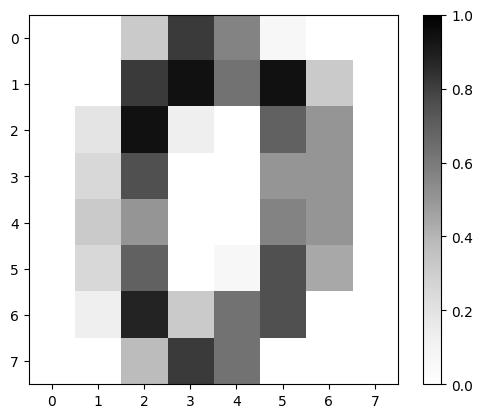

In [4]:
plt.imshow(x_data[0].reshape(8, 8), cmap="Greys", vmin=0, vmax=1)
plt.colorbar()
plt.show()

Now, we set up the autoencoder: it's just another neural network, where *halfway through the network* we have a "bottleneck layer". The bottleneck is *significantly* smaller than the inputs *and* the rest of the network:

* The input is 64 dimensional
* The hidden layers are 8 dimensional
* The bottleneck is only 2 dimensional. That is, *all* subsequent layers past the bottleneck will only receive whatever information is "compressed" into this 2D bottleneck.

In [5]:
input_dim = 64
hidden_dim = 8
bottleneck_dim = 2
output_dim = input_dim

params = {
    "layer_1": {
        "W": np.random.normal(size=(input_dim, hidden_dim)) / np.sqrt(input_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_2": {
        "W": np.random.normal(size=(hidden_dim, hidden_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_3": {
        "W": np.random.normal(size=(hidden_dim, bottleneck_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(bottleneck_dim,)),
    },
    "layer_4": {
    "W": np.random.normal(size=(bottleneck_dim, hidden_dim)) / np.sqrt(bottleneck_dim),
    "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_5": {
        "W": np.random.normal(size=(hidden_dim, output_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(output_dim,)),
    },
}

# Pay close attention to this function for the next question.
def predict_fn(params, X):
    X0 = X
    # remember, * is an elementwise multiply, whereas @ is a matrix multiply.
    X1 = jax.nn.relu(X0 @ params["layer_1"]["W"] + params["layer_1"]["b"])
    X2 = jax.nn.relu(X1 @ params["layer_2"]["W"] + params["layer_2"]["b"])
    X3 = X2 @ params["layer_3"]["W"] + params["layer_3"]["b"]
    X4 = jax.nn.relu(X3 @ params["layer_4"]["W"] + params["layer_4"]["b"])
    X5 = jax.nn.sigmoid(X4 @ params["layer_5"]["W"] + params["layer_5"]["b"])
    return {'reconstruct': X5, 'bottleneck': X3}

def loss_fn(params, X):
    reconstruct_X = predict_fn(params, X)['reconstruct']
    loss = -(X * jnp.log(reconstruct_X) + (1 - X) * jnp.log(1 - reconstruct_X))
    return jnp.mean(loss)

**Questions 2a**: Answer the following
* How many layers does this network have?
* Which layer is the "bottleneck layer"?
* How many layers does the encoder (the layers before bottleneck) and the decoder (the layers after the bottleneck) have?
* Why are they called "encoder" and "decoder"?
* Why are we returning `{'reconstruct': X5, 'bottleneck': X3}`? Why are these two values special?


ANS)
*   The network has five layers with learned weights, excluding the input layer.
*   Layer 3 is the bottleneck. It reduces the representation to only two values.
*   Encoder: Two layers before the bottleneck, plus the bottleneck layer itself Decoder: Two layers after the bottleneck.
* The encoder converts the original image into a smaller representation, and the decoder uses this representation to reconstruct the original image.
X5 contains the reconstructed images. We compare them with the originals to evaluate reconstruction quality.
* X3 contains the two-dimensional representations, and we use them to visualize how the network organizes images.







Now, let's train this model!

In [6]:
step_size = 0.01
total_steps = 3000

# We use an optimizer called Adam here.
# We won't go into detail, but think of it as "fast gradient descent"
optimizer = optax.adam(1e-3)
opt_state = optimizer.init(params)

grad_loss_fn = jax.grad(loss_fn)
grad_loss_fn = jax.jit(grad_loss_fn)

for i in range(total_steps):
    idxs = np.random.randint(low=0, high=x_data.shape[0], size=32)
    x_batch = x_data[idxs]
    # Remember, we compute gradients of the *first* argument, which is params.
    grad = grad_loss_fn(params, x_batch)
    update, opt_state = optimizer.update(grad, opt_state)
    params = optax.apply_updates(params, update)

    # We print the loss every 100 steps
    if i % 100 == 0:
        loss_val = loss_fn(params, x_data)
        print("Step:", i, "Loss:", loss_val)

Step: 0 Loss: 0.6943115
Step: 100 Loss: 0.56032044
Step: 200 Loss: 0.43939283
Step: 300 Loss: 0.42238933
Step: 400 Loss: 0.41875473
Step: 500 Loss: 0.41656855
Step: 600 Loss: 0.41465366
Step: 700 Loss: 0.41324422
Step: 800 Loss: 0.41157866
Step: 900 Loss: 0.41034526
Step: 1000 Loss: 0.4084299
Step: 1100 Loss: 0.40675223
Step: 1200 Loss: 0.40476337
Step: 1300 Loss: 0.4029317
Step: 1400 Loss: 0.4009094
Step: 1500 Loss: 0.3990118
Step: 1600 Loss: 0.39718452
Step: 1700 Loss: 0.39507878
Step: 1800 Loss: 0.39371243
Step: 1900 Loss: 0.3920334
Step: 2000 Loss: 0.3908896
Step: 2100 Loss: 0.38950056
Step: 2200 Loss: 0.38846695
Step: 2300 Loss: 0.3875145
Step: 2400 Loss: 0.38651735
Step: 2500 Loss: 0.38572067
Step: 2600 Loss: 0.38501474
Step: 2700 Loss: 0.38432816
Step: 2800 Loss: 0.3839676
Step: 2900 Loss: 0.38324532


Now, this network has two outputs: `reconstruct`, which is an attempt at reconstructing the original input, and `bottleneck`, which is the output of the bottleneck layer itself. Let's see the reconstruction vs the original:

In [7]:
predict_vals = predict_fn(params, x_data)

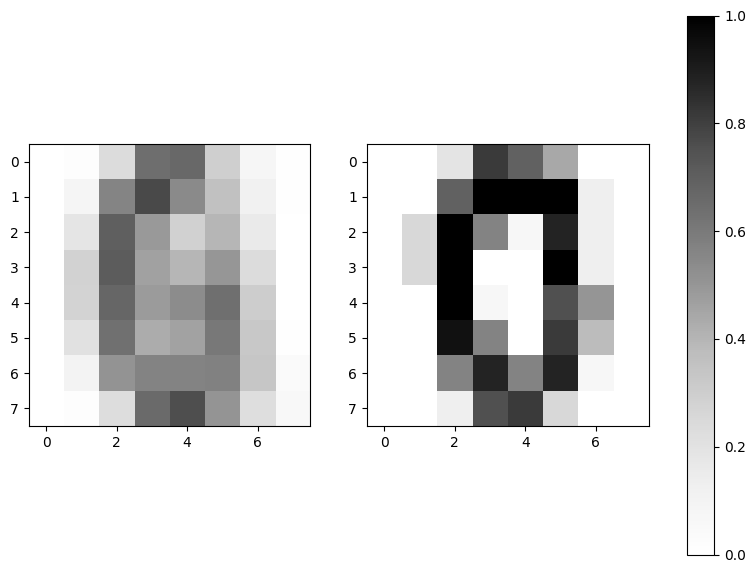

In [8]:
EXAMPLE_NUMBER = 20

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 7))
img0 = ax[0].imshow(predict_vals['reconstruct'][EXAMPLE_NUMBER].reshape(8, 8), vmin=0, vmax=1, cmap="Greys")
img1 = ax[1].imshow(x_data[EXAMPLE_NUMBER].reshape(8, 8), vmin=0, vmax=1, cmap="Greys")
fig.colorbar(img0, ax=ax)
plt.show()

**Question 2b**: `x_data` has 1797 examples. Try  different values of `EXAMPLE_NUMBER` within that range to see how well the model reconstructs the original. Qualitatively, how good are these reconstructions, and in what ways are they flawed?

ANS) The model reconstructs the general shapes of some handwritten digits, but the results are not always accurate. Many images appear blurry, and some important details disappear. In certain cases, different digits produce similar reconstructions, making them difficult to distinguish.

This happens because the bottleneck reduces 64 pixel values to only two numbers. The network cannot preserve every detail. It therefore learns patterns that help reduce reconstruction error.

We can also extract the bottleneck values. Since the layer is 2 dimensional, we can directly plot it as a scatter plot!

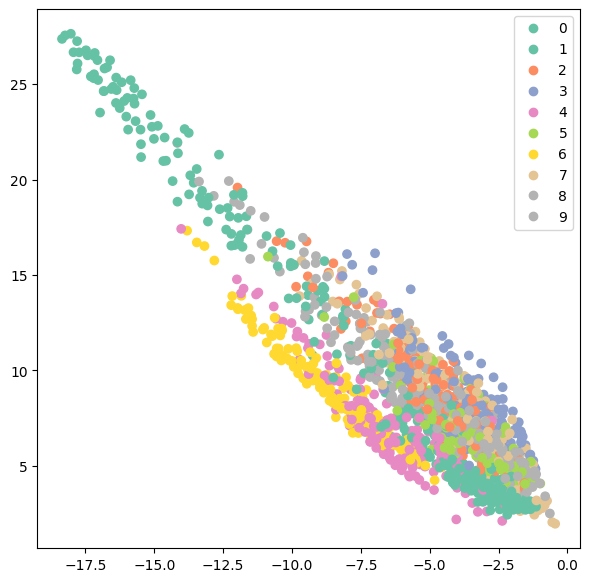

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(predict_vals['bottleneck'][:, 0], predict_vals['bottleneck'][:, 1], c=y_data, cmap="Set2")
ax.legend(handles=scatter.legend_elements()[0], labels=list(digits['target_names']))
plt.show()

**Questions 2c:**

1. What behavior do you see in the plot above? Are bottleneck vectors of images of the same digit closer or further apart?
2. What can you say about this plot, given that the model *never* sees the labels during training (it purely reconstructs every digit image as provided, with no additional information about what class it belongs to)?

ANS)
1) Some images of the same digit appear closer together, but the pattern is not consistent. The plot shows partial grouping, especially toward the upper-left. However, most digit classes overlap considerably in the center and lower-right. Therefore, the bottleneck does not clearly separate all ten digits.


2) This suggests that the autoencoder learns some meaningful patterns without knowing the digit labels. It learns only by reconstructing the original images. Similar image features can produce nearby representations, even without labeled training data. However, the overlapping groups show that accurate reconstruction does not necessarily require separating digits into distinct classes.

### Question 3: A better autoencoder (4)

In the code cells below:
* Modify the code above, to extend the model's encoder and decoders from 2 layers to 3 layers each. (This means updating both the forward pass, and the weight initialization)
* Rerun training with this modified model, and record the loss you obtain. Is it better than in question 2?

You may copy any of the code from the cells above as needed, and modify them.

ANS) I modified the original autoencoder by adding one layer before the bottleneck and another after it. This increased the network from five to seven learned layers, while keeping the bottleneck at two dimensions.

After training both models for 3,000 steps, the original model achieved a reconstruction loss of 0.3712. The deeper model achieved a slightly higher loss of 0.3813.

Therefore, the deeper model did not perform better in this experiment. Although additional layers can learn more complex relationships, they also make training more difficult. I think this explains why adding layers did not automatically improve reconstruction. Different initial weights or additional training might produce different results.

## Initializing both models

In [10]:

# Creating the same starting conditions for both models
def make_params(sizes):
    rng = np.random.default_rng(101)
    new_params = {}

    for i in range(len(sizes) - 1):
        in_size = sizes[i]
        out_size = sizes[i + 1]

        new_params[f"layer_{i+1}"] = {
            "W": jnp.array(rng.normal(size=(in_size, out_size)) / np.sqrt(in_size), dtype=jnp.float32),
            "b": jnp.zeros(out_size)
        }

    return new_params

# Setting the original and deeper layer sizes
base_sizes = [64, 8, 8, 2, 8, 64]
deep_sizes = [64, 8, 8, 8, 2, 8, 8, 64]

base_params = make_params(base_sizes)
deep_params = make_params(deep_sizes)

# Preparing the same input data
x_data = jnp.array(digits["data"] / 16, dtype=jnp.float32)


## Updating the forward pass

In [12]:

def deep_predict_fn(params, X):
    # Encoding the input through three layers
    X1 = jax.nn.relu(X @ params["layer_1"]["W"] + params["layer_1"]["b"])
    X2 = jax.nn.relu(X1 @ params["layer_2"]["W"] + params["layer_2"]["b"])
    X3 = jax.nn.relu(X2 @ params["layer_3"]["W"] + params["layer_3"]["b"])

    # Creating the two-dimensional bottleneck
    X4 = X3 @ params["layer_4"]["W"] + params["layer_4"]["b"]

    # Reconstructing the input through three layers
    X5 = jax.nn.relu(X4 @ params["layer_5"]["W"] + params["layer_5"]["b"])
    X6 = jax.nn.relu(X5 @ params["layer_6"]["W"] + params["layer_6"]["b"])
    X7 = jax.nn.sigmoid(X6 @ params["layer_7"]["W"] + params["layer_7"]["b"])

    return {"reconstruct": X7, "bottleneck": X4}

def deep_loss_fn(params, X):
    # Comparing the reconstruction with the original input
    reconstructed = deep_predict_fn(params, X)["reconstruct"]
    reconstructed = jnp.clip(reconstructed, 1e-7, 1 - 1e-7)

    loss = -(X * jnp.log(reconstructed) + (1 - X) * jnp.log(1 - reconstructed))
    return jnp.mean(loss)


## Training and comparing both networks

In [13]:

# Preparing identical training batches
total_steps = 3000
rng = np.random.default_rng(2345)
batches = rng.integers(0, len(x_data), size=(total_steps, 32))

def train_model(params, calc_loss):
    optimizer = optax.adam(1e-3)
    state = optimizer.init(params)

    @jax.jit
    def train_step(params, state, batch):
        # Calculating gradients and updating weights
        grad = jax.grad(calc_loss)(params, batch)
        updates, state = optimizer.update(grad, state)
        params = optax.apply_updates(params, updates)
        return params, state

    # Training the model on the selected batches
    for idx in batches:
        params, state = train_step(params, state, x_data[idx])

    return params

# Training both models
base_params = train_model(base_params, loss_fn)
deep_params = train_model(deep_params, deep_loss_fn)

# Calculating reconstruction losses
base_loss = float(loss_fn(base_params, x_data))
deep_loss = float(deep_loss_fn(deep_params, x_data))

print("Original model loss:", round(base_loss, 4))
print("Deeper model loss:", round(deep_loss, 4))
print("Is the deeper model better?", deep_loss < base_loss)


Original model loss: 0.3712
Deeper model loss: 0.3813
Is the deeper model better? False


## Visualizing the deeper model

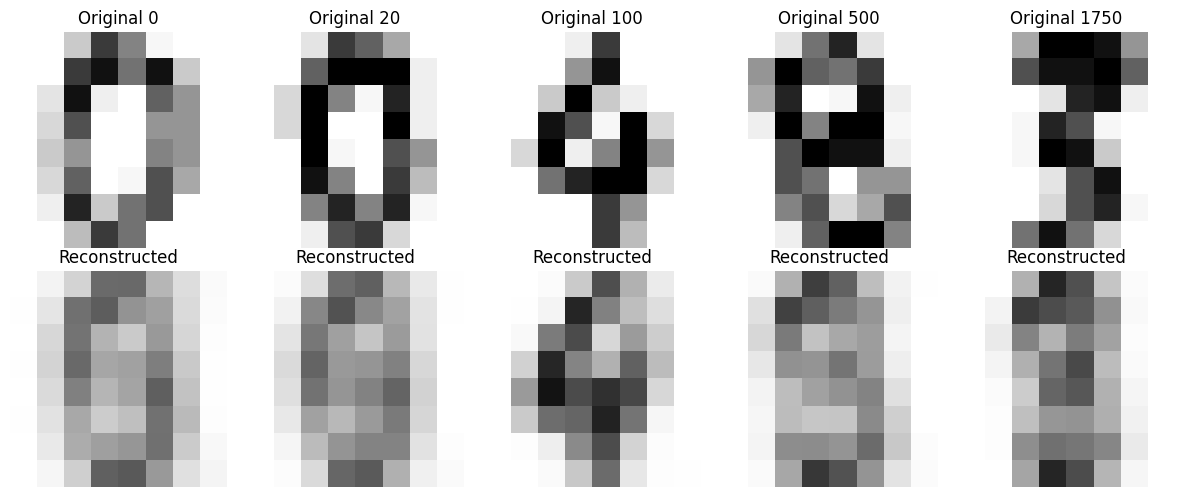

In [14]:

# Reconstructing several handwritten digits
results = deep_predict_fn(deep_params, x_data)

examples = [0, 20, 100, 500, 1750]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, num in enumerate(examples):
    # Showing the original image
    axes[0, i].imshow(np.array(x_data[num]).reshape(8, 8), cmap="Greys", vmin=0, vmax=1)
    axes[0, i].set_title(f"Original {num}")
    axes[0, i].axis("off")

    # Showing the reconstructed image
    axes[1, i].imshow(np.array(results["reconstruct"][num]).reshape(8, 8), cmap="Greys", vmin=0, vmax=1)
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()
